In [1]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import gc #liberacion de memoria ram.
import funciones

from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

In [2]:
#Cargar datos de entrenamiento
X_train = np.load(f'./X_train_750k_8020.npy') 
y_train = np.load(f'./y_train_750k_8020.npy').ravel()

In [2]:
# cargar datos de validacion
X_validacion = np.load('validation_data.npy', mmap_mode='r')
with open('validation_data.npy', 'rb') as f:
    _ = np.load(f) # Salto de X
    y_validacion = np.load(f).ravel()

In [3]:
X_validacion

memmap([[-1.        ,  0.32544303, -0.14577755, ...,         nan,
                 nan,         nan],
        [-1.        ,  0.9651718 ,  0.77658683, ...,         nan,
                 nan,         nan],
        [ 1.        ,  0.80953467,  0.00331702, ...,         nan,
                 nan,         nan],
        ...,
        [-1.        ,  0.64526194,  0.30491933, ...,         nan,
                 nan,         nan],
        [ 1.        ,  0.7541175 ,  0.5814422 , ...,         nan,
                 nan,         nan],
        [-1.        ,  0.920797  , -0.34873384, ...,         nan,
                 nan,         nan]], shape=(731273, 190), dtype=float32)

In [5]:
a=(731273/4781717)*100
a

15.293104966270485

In [6]:
modelo_base = lgb.LGBMClassifier(
    learning_rate=0.1,
    num_leaves=255,            
    num_trees=500,          
    n_jobs=7,                 
    #num_threads= 16,
    min_data_in_leaf = 0,
    min_sum_hessian_in_leaf = 100
)

modelo_regularizado2 = lgb.LGBMClassifier(
    learning_rate=0.1,
    num_leaves=100,
    max_depth=8,            
    num_trees=500,          
    n_jobs=7,                 
    #num_threads= 16,
    min_data_in_leaf = 100,
    min_sum_hessian_in_leaf = 100
)

import lightgbm as lgb

modelo_regularizado = lgb.LGBMClassifier(
    # 1. Control del ritmo de aprendizaje
    learning_rate=0.03,          # Bajamos el paso para que el aprendizaje sea más suave y robusto
    num_trees=1000,              # Subimos árboles, pero lo ideal es combinarlo con Early Stopping

    # 2. Restricción de la estructura del árbol (Los frenos principales)
    num_leaves=63,               # Reducimos drásticamente la complejidad por árbol (estaba en 255)
    max_depth=8,                 # Ponemos un tope explícito a la profundidad para evitar interacciones ruidosas
    
    # 3. Restricción del contenido de las hojas (Crucial para sets grandes)
    min_data_in_leaf=100,        # Obliga a que cada hoja tenga al menos 100 eventos (estaba en 0)
    min_sum_hessian_in_leaf=300, # Aumentamos la confianza mínima para permitir divisiones (estaba en 100)

    # 4. Inyección de aleatoriedad (Evita que se obsesione con variables espejo)
    feature_fraction=0.7,        # Cada árbol verá solo el 70% de tus 190 variables de forma aleatoria
    bagging_fraction=0.8,        # Cada árbol entrenará con el 80% de los datos escogidos al azar
    bagging_freq=5,              # Frecuencia con la que se hace el remuestreo de datos

    # 5. Penalizaciones matemáticas directas (Regularización L1 y L2)
    reg_alpha=2.0,               # Regularización L1 (Lasso): Tiende a "apagar" pesos de hojas ruidosas
    reg_lambda=5.0,              # Regularización L2 (Ridge): Suaviza los pesos extremos en las hojas
    
    n_jobs = 7,              # Usamos solo este parámetro para controlar el paralelismo
    random_state=42
)
#modelo_regularizado.fit(X_train, y_train)
modelo_regularizado2.fit(X_train, y_train)
#modelo_base.fit(X_train, y_train)

/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/lightgbm/engine.py:177: UserWarning: Found `num_trees` in params. Will use it instead of argument
  _log_warning(f"Found `{alias}` in params. Will use it instead of argument")


[LightGBM] [Warning] min_sum_hessian_in_leaf is set=100, min_child_weight=0.001 will be ignored. Current value: min_sum_hessian_in_leaf=100
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Warning] num_iterations is set=500, num_trees=500 will be ignored. Current value: num_iterations=500


LGBMClassifier(max_depth=8, min_data_in_leaf=100, min_sum_hessian_in_leaf=100,
               n_jobs=7, num_leaves=100, num_trees=500)

/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


                 train  test
Exactitud (0.5)   0.71  0.74
Exactitud Max     0.71  0.74
F1 (0.5)          0.71  0.74
F1 Max            0.73  0.76
APS               0.79  0.84
ROC AUC           0.79  0.83


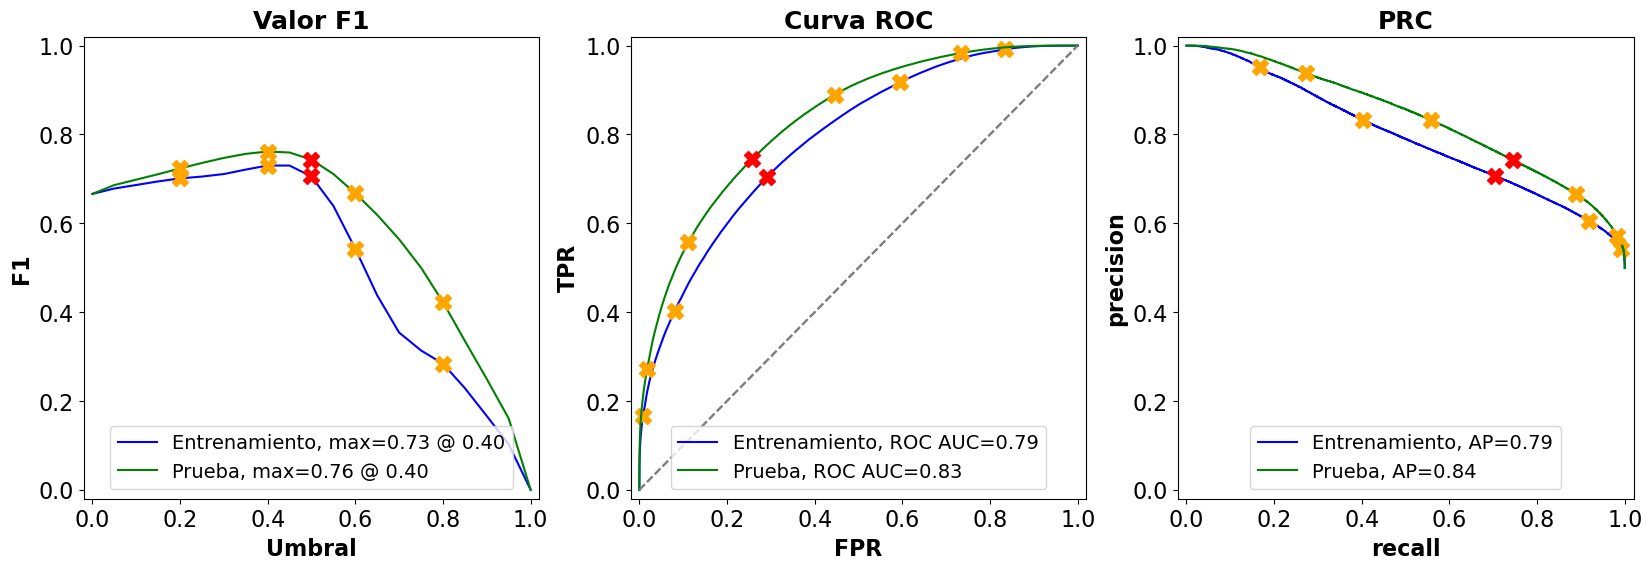

In [5]:
stats_df, fig = funciones.evaluate_model(modelo_regularizado, X_train, y_train, X_validacion, y_validacion)

/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


                 train  test
Exactitud (0.5)   0.75  0.75
Exactitud Max     0.75  0.75
F1 (0.5)          0.75  0.74
F1 Max            0.76  0.76
APS               0.84  0.84
ROC AUC           0.83  0.84


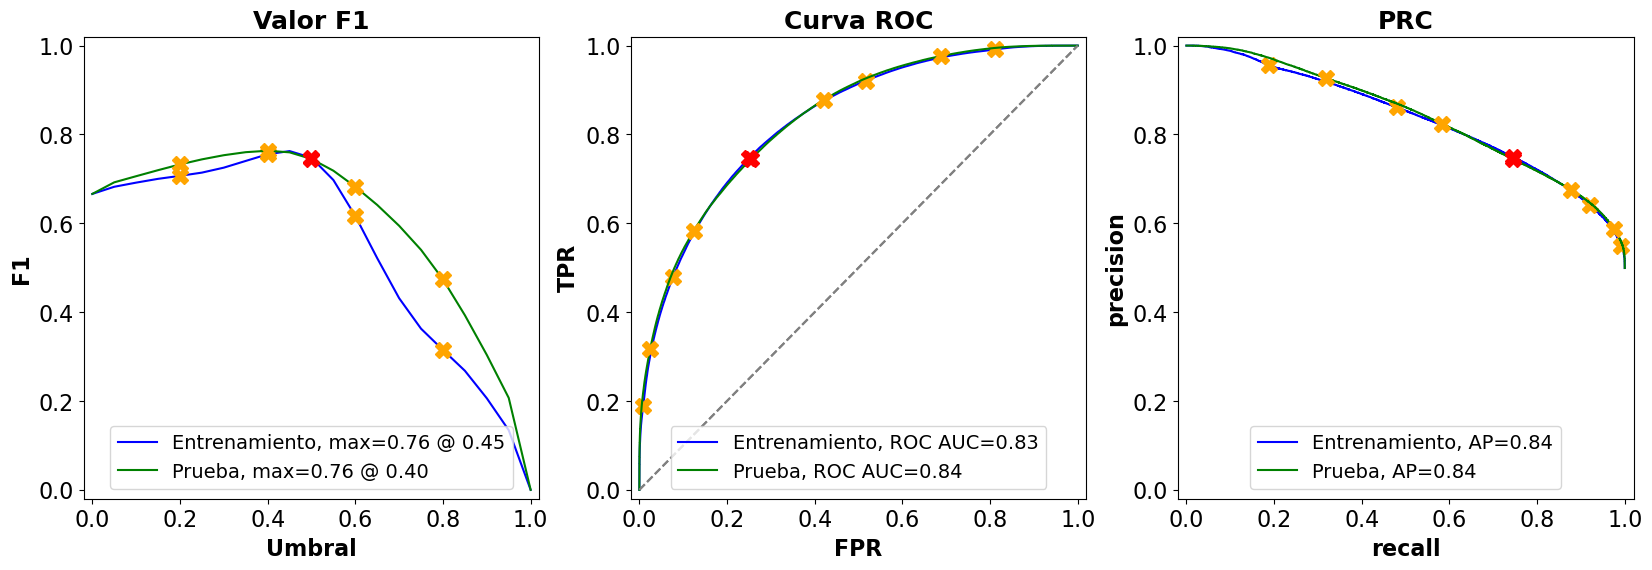

In [7]:
stats_df, fig = funciones.evaluate_model(modelo_regularizado2, X_train, y_train, X_validacion, y_validacion)

/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


                 train  test
Exactitud (0.5)   0.86  0.75
Exactitud Max     0.86  0.75
F1 (0.5)          0.86  0.75
F1 Max            0.86  0.76
APS               0.93  0.84
ROC AUC           0.93  0.84


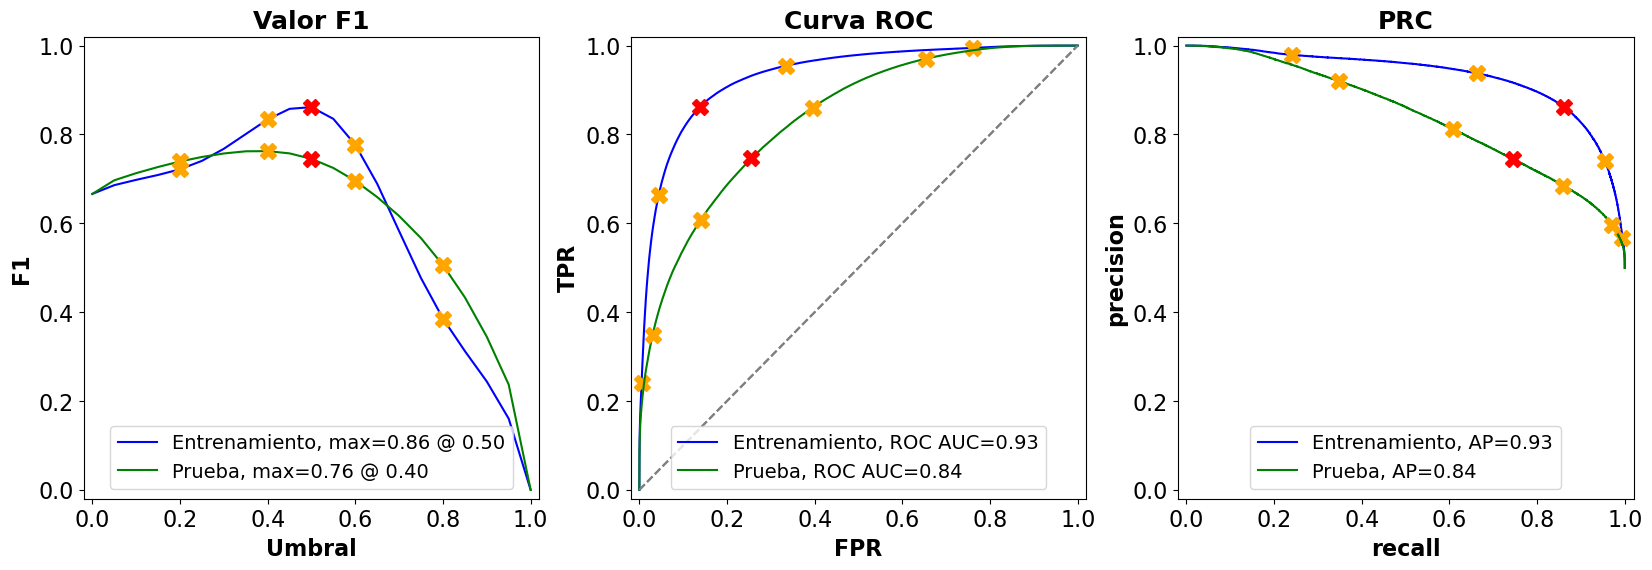

In [8]:
stats_df, fig = funciones.evaluate_model(modelo_base, X_train, y_train, X_validacion, y_validacion)

In [1]:
import lightgbm as lgb
#from lightgbm import LGBMClassifier
import pandas as pd
import numpy as np
import pickle
import funciones
from ejecucion_AG_TI import mutation_func, mutation_func2, fitness_exp, callback_generacion
import matplotlib.pyplot as plt 
# --- CONFIGURACIÓN ---
metodo = 'wrapped_lgb' # wrapped_lgb, inconsistencia, hibrida
experimento = 'experimento1'
escalas = ['10k', '100k', '750k']

#Cargar nombre de las 190 caracteristicas
with open('./nombre_variables_b_flavor.pkl', 'rb') as f:
    nombre_caracteristicas = pickle.load(f)['nombre_caracteristicas']

# cargar datos de validacion
X_validacion = np.load('validation_data.npy', mmap_mode='r')
with open('validation_data.npy', 'rb') as f:
    _ = np.load(f) # Salto de X
    y_validacion = np.load(f).ravel()

# Diccionario para guardar el reporte final de cada escala
reporte_global = {}
conteo_variables = {}

# --- BUCLE DE ENTRENAMIENTO ---
for num in escalas:
    print(f"\n" + "="*50)
    print(f"PROCESANDO ESCALA: {num}")
    print("="*50)

    #cargar entrenamiento específico
    X_train = np.load(f'./X_train_{num}_8020.npy') 
    y_train = np.load(f'./y_train_{num}_8020.npy').ravel()
    

    #extraer variables ganadoras (Solución de Compromiso / Punto Ideal)
    resumen_path = f'./{experimento}/resultado{num}/resumen_{num}_{metodo}.pkl'
    vars_ganadoras = funciones.extraccion_caracteristicas_compromiso(resumen_path)
    conteo_variables[num] = len(vars_ganadoras)
    print(f'NUMERO DE VARIABLES: {len(vars_ganadoras)}')
    #mapear nombres a índices
    indices = [nombre_caracteristicas.index(v) for v in vars_ganadoras]
    
    # Filtrar conjuntos
    X_train_opt = X_train[:, indices]
    print(f'Numero de variables de este experimento:{X_train_opt.shape}')
    X_val_opt = X_validacion[:, indices]

    # Entrenar Modelo
    baseline = lgb.LGBMClassifier(
        learning_rate=0.1,
        num_leaves=100,
        max_depth=8,            
        num_trees=500,          
        n_jobs=7,                 
    #num_threads= 16,
        min_data_in_leaf = 100,
        min_sum_hessian_in_leaf = 100
    )

    baseline.fit(X_train_opt, y_train)

    # Evaluar y Graficar
    stats_df, fig = funciones.evaluate_model(baseline, X_train_opt, y_train, X_val_opt, y_validacion)
    
    # Guardar resultados
    fig.savefig(f'./{experimento}/eval_final_{metodo}_{num}.pdf', bbox_inches='tight')
    reporte_global[num] = stats_df
    plt.close(fig)

print("\n>>> PROCESO COMPLETADO <<<")


PROCESANDO ESCALA: 10k
NUMERO DE VARIABLES: 49
Numero de variables de este experimento:(10000, 49)


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/lightgbm/engine.py:177: UserWarning: Found `num_trees` in params. Will use it instead of argument
  _log_warning(f"Found `{alias}` in params. Will use it instead of argument")


[LightGBM] [Warning] min_sum_hessian_in_leaf is set=100, min_child_weight=0.001 will be ignored. Current value: min_sum_hessian_in_leaf=100
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Warning] num_iterations is set=500, num_trees=500 will be ignored. Current value: num_iterations=500


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


                 train  test
Exactitud (0.5)   0.88  0.64
Exactitud Max     0.88  0.64
F1 (0.5)          0.88  0.63
F1 Max            0.88  0.70
APS               0.95  0.70
ROC AUC           0.95  0.71

PROCESANDO ESCALA: 100k
NUMERO DE VARIABLES: 73
Numero de variables de este experimento:(100000, 73)


...

                 train  test
Exactitud (0.5)   0.81  0.69
Exactitud Max     0.81  0.69
F1 (0.5)          0.81  0.69
F1 Max            0.81  0.72
APS               0.89  0.78
ROC AUC           0.89  0.77

PROCESANDO ESCALA: 750k
NUMERO DE VARIABLES: 64
Numero de variables de este experimento:(750000, 64)


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/lightgbm/engine.py:177: UserWarning: Found `num_trees` in params. Will use it instead of argument
  _log_warning(f"Found `{alias}` in params. Will use it instead of argument")


[LightGBM] [Warning] min_sum_hessian_in_leaf is set=100, min_child_weight=0.001 will be ignored. Current value: min_sum_hessian_in_leaf=100
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Warning] num_iterations is set=500, num_trees=500 will be ignored. Current value: num_iterations=500


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


                 train  test
Exactitud (0.5)   0.72  0.72
Exactitud Max     0.72  0.72
F1 (0.5)          0.71  0.72
F1 Max            0.74  0.75
APS               0.80  0.81
ROC AUC           0.80  0.81

>>> PROCESO COMPLETADO <<<


In [2]:
# ==============================================================================
# --- GENERACIÓN AUTOMÁTICA DE CUADRO(INCLUYENDO BASELINE) ---
# ==============================================================================

filas_tabla = []

#Procesar los resultados guardados en el bucle para las escalas optimizadas
for num in escalas:
    df_escala = reporte_global[num]
    
    # Extraemos los valores usando los índices exactos de tus gráficas de diagnóstico
    # Usamos .get() o condiciones por si acaso cambia el nombre exacto
    acc_tr = df_escala.loc['Exactitud Max', 'train']
    acc_va = df_escala.loc['Exactitud Max', 'test']
    
    f1_tr  = df_escala.loc['F1 Max', 'train']
    f1_va  = df_escala.loc['F1 Max', 'test']
    
    auc_tr = df_escala.loc['ROC AUC', 'train']
    auc_va = df_escala.loc['ROC AUC', 'test']
    
    aps_tr = df_escala.loc['APS', 'train']
    aps_va = df_escala.loc['APS', 'test']
    
    filas_tabla.append({
        'Escala': num,
        'Vars': conteo_variables[num],
        'Acc_Tr': acc_tr, 'Acc_Va': acc_va,
        'F1_Tr': f1_tr,   'F1_Va': f1_va,
        'AUC_Tr': auc_tr, 'AUC_Va': auc_va,
        'APS_Tr': aps_tr, 'APS_Va': aps_va
    })

#AGREGAR MANUALMENTE LA FILA DEL BASELINE REGULARIZADO (190 VARS)
filas_tabla.append({
    'Escala': '750k (Base)',
    'Vars': 190,
    'Acc_Tr': 0.750, 'Acc_Va': 0.750,
    'F1_Tr': 0.760,  'F1_Va': 0.760,  # Usando F1 Max
    'AUC_Tr': 0.830, 'AUC_Va': 0.840,
    'APS_Tr': 0.840, 'APS_Va': 0.840
})

# Crear un DataFrame con MultiIndex en las columnas para simular el formato LaTeX
columnas_multi = pd.MultiIndex.from_tuples([
    ('Escala', ''), ('Vars', ''),
    ('Exactitud', 'Entr.'), ('Exactitud', 'Val.'), ('Exactitud', 'Dif.'),
    ('F1-Score', 'Entr.'), ('F1-Score', 'Val.'), ('F1-Score', 'Dif.'),
    ('ROC AUC', 'Entr.'),  ('ROC AUC', 'Val.'),  ('ROC AUC', 'Dif.'),
    ('APS', 'Entr.'),      ('APS', 'Val.'),      ('APS', 'Dif.')
])

datos_formateados = []
for f in filas_tabla:

    diff_acc = -(f['Acc_Va'] - f['Acc_Tr'])
    diff_f1  = -(f['F1_Va']  - f['F1_Tr'])
    diff_auc = -(f['AUC_Va'] - f['AUC_Tr'])
    diff_aps = -(f['APS_Va'] - f['APS_Tr'])

    datos_formateados.append([
        f['Escala'],
        f['Vars'],
        f"{f['Acc_Tr']:.3f}", f"{f['Acc_Va']:.3f}", f"{diff_acc:+.3f}",
        f"{f['F1_Tr']:.3f}",  f"{f['F1_Va']:.3f}",  f"{diff_f1:+.3f}",
        f"{f['AUC_Tr']:.3f}", f"{f['AUC_Va']:.3f}", f"{diff_auc:+.3f}",
        f"{f['APS_Tr']:.3f}", f"{f['APS_Va']:.3f}", f"{diff_aps:+.3f}"
    ])

df_cuadro3 = pd.DataFrame(datos_formateados, columns=columnas_multi)

# Imprimir en consola la tabla limpia en formato texto
print("\n" + "="*40)
print("CUADRO 3: VISTA PREVIA EN TEXTO")
print("="*40)
print(df_cuadro3.to_string(index=False))

# ==============================================================================
# --- GENERACIÓN AUTOMÁTICA DEL CÓDIGO LATEX ENHANCED (MÁS GRANDE Y LEGIBLE) ---
# ==============================================================================

# 1. Generar la estructura tabular base
tabular_latex = df_cuadro3.style.hide(axis='index').to_latex(
    hrules=True,                    # Genera \toprule, \midrule, \bottomrule
    column_format='llcccccccccccc',    # 2 texto + 12 numéricas centradas
    multicol_align='c'              # Centra los encabezados padres
)

# Convertimos los \cline en \cmidrule(lr) para mantener el estilo recortado profesional
tabular_latex = tabular_latex.replace(r'\cline', r'\cmidrule(lr)')

tabular_latex = tabular_latex.replace('Escala', r'\textbf{Escala}')
tabular_latex = tabular_latex.replace('Vars', r'\textbf{Vars}')
tabular_latex = tabular_latex.replace('Exactitud', r'\textbf{Exactitud}')
tabular_latex = tabular_latex.replace('F1-Score', r'\textbf{F1-Score}')
tabular_latex = tabular_latex.replace('ROC AUC', r'\textbf{ROC AUC}')
tabular_latex = tabular_latex.replace('APS', r'\textbf{APS}')

# Subencabezados de las muestras
tabular_latex = tabular_latex.replace('Entr.', r'\textbf{Entr.}')
tabular_latex = tabular_latex.replace('Val.', r'\textbf{Val.}')
tabular_latex = tabular_latex.replace('Dif.', r'\textbf{Dif.}')
# 2. Construir el bloque flotante inyectando los modificadores de escala desde Python
# Duplicamos las llaves angulares {{ }} debido a las reglas de los f-strings de Python
tabla_completa_latex = f"""\\begin{{table}}[htbp]
\\centering
\\caption{{Comparativa  métricas de evaluación por escala de eventos.  (Modelo
entrenado con el mismo número de eventos usados en la selección de variables)}}
\\label{{}}
\\setlength{{\\tabcolsep}}{{2.5pt}} % <--- Reduce el espacio muerto inter-columna para que la letra crezca
\\makebox[\\textwidth][c]{{       % <---  Centra la tabla permitiendo que use un poco de los márgenes
    \\resizebox{{1.06\\textwidth}}{{!}}{{ % <--- Incrementamos al 106% del ancho para ganar tamaño de letra
{tabular_latex.strip()}
    }}
}}
\\end{{table}}"""

# 3. Imprimir el bloque final listo para Overleaf
print("\n" + "="*60)
print("CÓDIGO LATEX OPTIMIZADO (MÁS GRANDE)")
print("="*60)
print(tabla_completa_latex)


CUADRO 3: VISTA PREVIA EN TEXTO
     Escala Vars Exactitud              F1-Score              ROC AUC                APS             
                     Entr.  Val.   Dif.    Entr.  Val.   Dif.   Entr.  Val.   Dif. Entr.  Val.   Dif.
        10k   49     0.880 0.640 +0.240    0.880 0.700 +0.180   0.950 0.710 +0.240 0.950 0.700 +0.250
       100k   73     0.810 0.690 +0.120    0.810 0.720 +0.090   0.890 0.770 +0.120 0.890 0.780 +0.110
       750k   64     0.720 0.720 -0.000    0.740 0.750 -0.010   0.800 0.810 -0.010 0.800 0.810 -0.010
750k (Base)  190     0.750 0.750 -0.000    0.760 0.760 -0.000   0.830 0.840 -0.010 0.840 0.840 -0.000

CÓDIGO LATEX OPTIMIZADO (MÁS GRANDE)
\begin{table}[htbp]
\centering
\caption{Comparativa  métricas de evaluación por escala de eventos.  (Modelo
entrenado con el mismo número de eventos usados en la selección de variables)}
\label{}
\setlength{\tabcolsep}{2.5pt} % <--- Reduce el espacio muerto inter-columna para que la letra crezca
\makebox[\textwidth]


PROCESANDO ESCALA: 10k
NUMERO DE VARIABLES: 49
Numero de variables de este experimento:(750000, 49)


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/lightgbm/engine.py:177: UserWarning: Found `num_trees` in params. Will use it instead of argument
  _log_warning(f"Found `{alias}` in params. Will use it instead of argument")


[LightGBM] [Warning] min_sum_hessian_in_leaf is set=100, min_child_weight=0.001 will be ignored. Current value: min_sum_hessian_in_leaf=100
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Warning] num_iterations is set=500, num_trees=500 will be ignored. Current value: num_iterations=500


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


                 train  test
Exactitud (0.5)   0.69  0.69
Exactitud Max     0.69  0.69
F1 (0.5)          0.69  0.69
F1 Max            0.72  0.73
APS               0.77  0.78
ROC AUC           0.77  0.77

PROCESANDO ESCALA: 100k
NUMERO DE VARIABLES: 73
Numero de variables de este experimento:(750000, 73)


...

                 train  test
Exactitud (0.5)   0.71  0.70
Exactitud Max     0.71  0.70
F1 (0.5)          0.71  0.70
F1 Max            0.73  0.74
APS               0.78  0.80
ROC AUC           0.78  0.79

PROCESANDO ESCALA: 750k
NUMERO DE VARIABLES: 64
Numero de variables de este experimento:(750000, 64)


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/lightgbm/engine.py:177: UserWarning: Found `num_trees` in params. Will use it instead of argument
  _log_warning(f"Found `{alias}` in params. Will use it instead of argument")


[LightGBM] [Warning] min_sum_hessian_in_leaf is set=100, min_child_weight=0.001 will be ignored. Current value: min_sum_hessian_in_leaf=100
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Warning] num_iterations is set=500, num_trees=500 will be ignored. Current value: num_iterations=500


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


                 train  test
Exactitud (0.5)   0.72  0.72
Exactitud Max     0.72  0.72
F1 (0.5)          0.71  0.72
F1 Max            0.74  0.75
APS               0.80  0.81
ROC AUC           0.80  0.81

>>> PROCESO COMPLETADO <<<


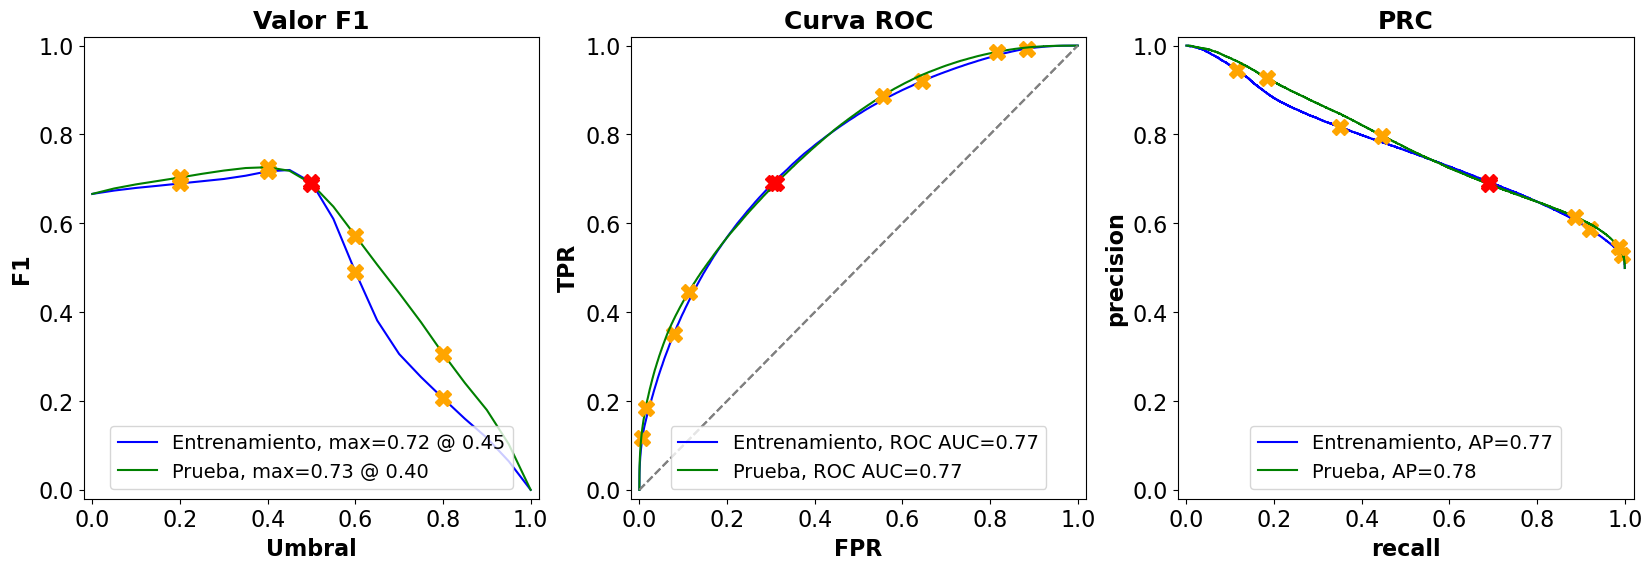

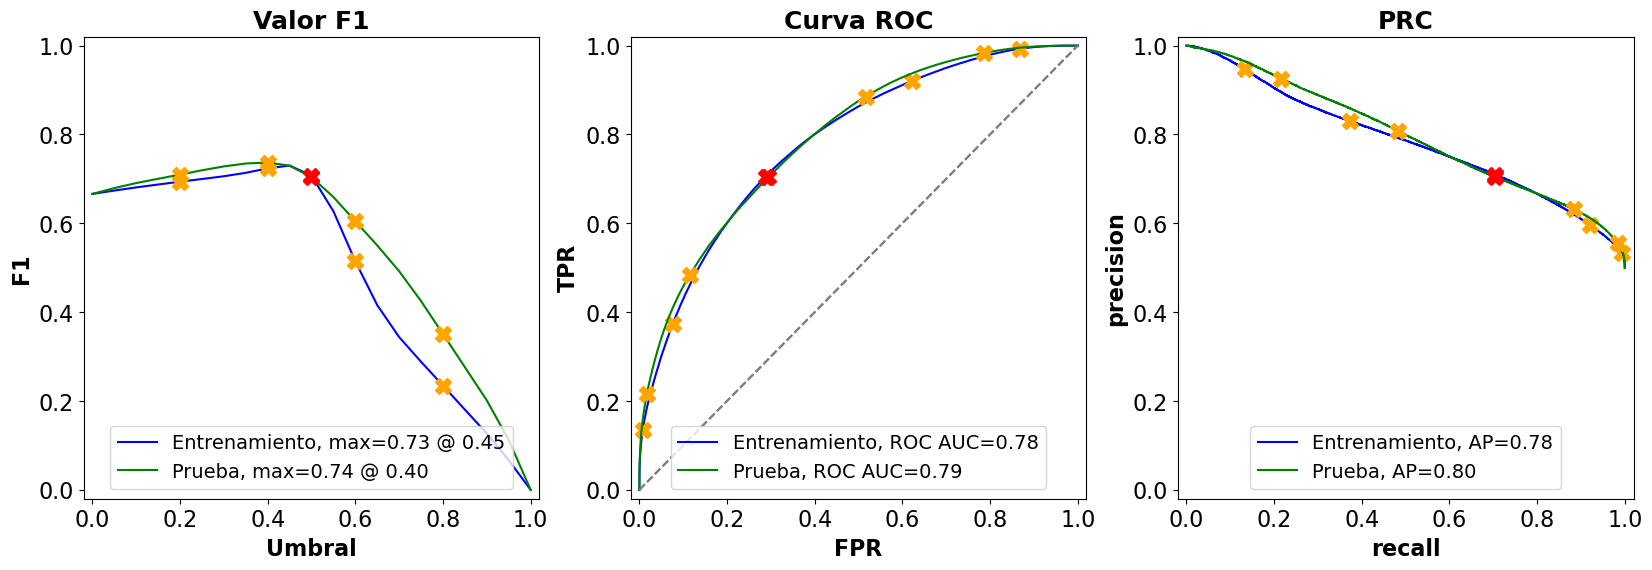

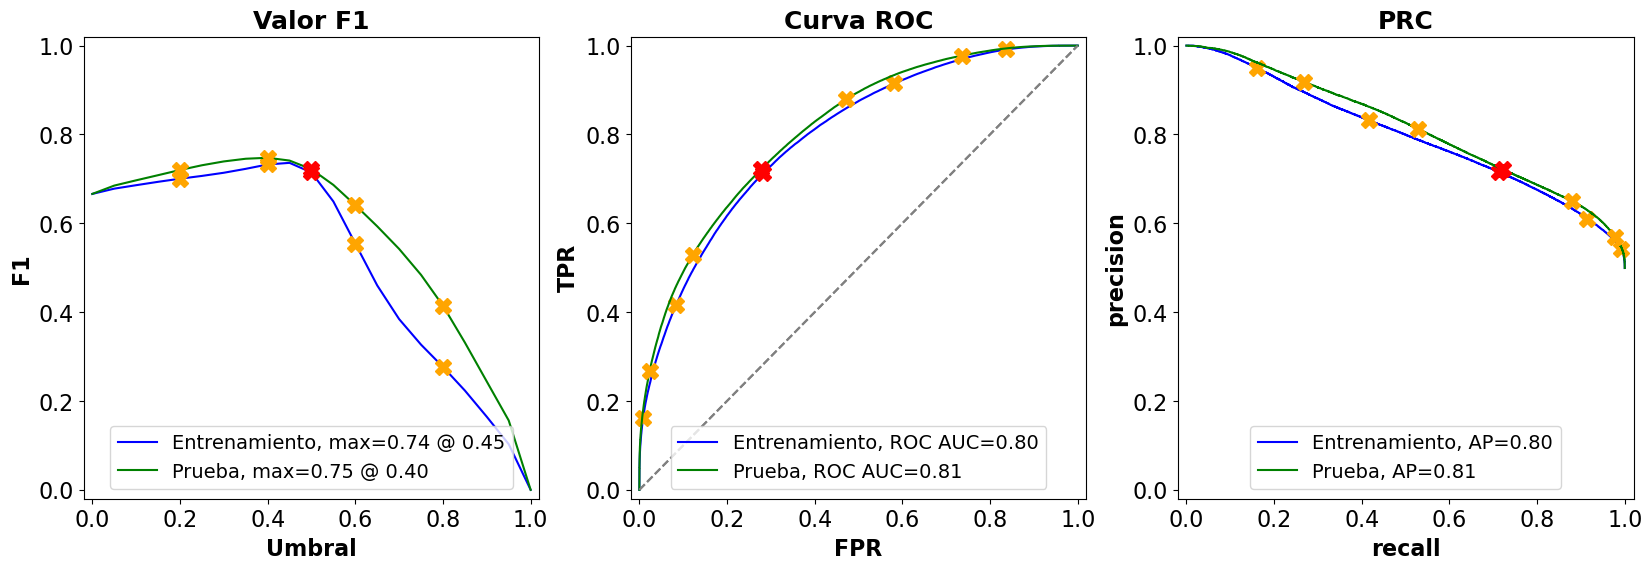

In [1]:
###########################VALIDACION TODOS CON 750K EVENTOS

import lightgbm as lgb
#from lightgbm import LGBMClassifier
import pandas as pd
import numpy as np
import pickle
import funciones
from ejecucion_AG_TI import mutation_func, mutation_func2, fitness_exp, callback_generacion
import matplotlib.pyplot as plt 
# --- CONFIGURACIÓN ---
metodo = 'wrapped_lgb' # wrapped_lgb, inconsistencia, hibrida
experimento = 'experimento1'
escalas = ['10k', '100k', '750k']

#Cargar nombre de las 190 caracteristicas
with open('./nombre_variables_b_flavor.pkl', 'rb') as f:
    nombre_caracteristicas = pickle.load(f)['nombre_caracteristicas']

# cargar datos de validacion
X_validacion = np.load('validation_data.npy', mmap_mode='r')
with open('validation_data.npy', 'rb') as f:
    _ = np.load(f) # Salto de X
    y_validacion = np.load(f).ravel()

# Diccionario para guardar el reporte final de cada escala
reporte_global = {}
conteo_variables = {}

#cargar entrenamiento específico
X_train = np.load(f'./X_train_750k_8020.npy') 
y_train = np.load(f'./y_train_750k_8020.npy').ravel()
# --- BUCLE DE ENTRENAMIENTO ---
for num in escalas:
    print(f"\n" + "="*50)
    print(f"PROCESANDO ESCALA: {num}")
    print("="*50)
    

    #extraer variables ganadoras (Solución de Compromiso / Punto Ideal)
    resumen_path = f'./{experimento}/resultado{num}/resumen_{num}_{metodo}.pkl'
    vars_ganadoras = funciones.extraccion_caracteristicas_compromiso(resumen_path)
    conteo_variables[num] = len(vars_ganadoras)
    print(f'NUMERO DE VARIABLES: {len(vars_ganadoras)}')
    #mapear nombres a índices
    indices = [nombre_caracteristicas.index(v) for v in vars_ganadoras]
    
    # Filtrar conjuntos
    X_train_opt = X_train[:, indices]
    print(f'Numero de variables de este experimento:{X_train_opt.shape}')
    X_val_opt = X_validacion[:, indices]

    # Entrenar Modelo
    baseline = lgb.LGBMClassifier(
        learning_rate=0.1,
        num_leaves=100,
        max_depth=8,            
        num_trees=500,          
        n_jobs=7,                 
    #num_threads= 16,
        min_data_in_leaf = 100,
        min_sum_hessian_in_leaf = 100
    )

    baseline.fit(X_train_opt, y_train)

    # Evaluar y Graficar
    stats_df, fig = funciones.evaluate_model(baseline, X_train_opt, y_train, X_val_opt, y_validacion)
    
    # Guardar resultados
    #fig.savefig(f'./{experimento}/eval_final_{metodo}_{num}.pdf', bbox_inches='tight')
    reporte_global[num] = stats_df
    #plt.close(fig)

print("\n>>> PROCESO COMPLETADO <<<")

In [2]:
# ==============================================================================
# --- GENERACIÓN AUTOMÁTICA DE CUADRO(INCLUYENDO BASELINE) ---
# ==============================================================================

filas_tabla = []

#Procesar los resultados guardados en el bucle para las escalas optimizadas
for num in escalas:
    df_escala = reporte_global[num]
    
    # Extraemos los valores usando los indices exactos de las graficas de diagnostico
    
    acc_tr = df_escala.loc['Exactitud Max', 'train']
    acc_va = df_escala.loc['Exactitud Max', 'test']
    
    f1_tr  = df_escala.loc['F1 Max', 'train']
    f1_va  = df_escala.loc['F1 Max', 'test']
    
    auc_tr = df_escala.loc['ROC AUC', 'train']
    auc_va = df_escala.loc['ROC AUC', 'test']
    
    aps_tr = df_escala.loc['APS', 'train']
    aps_va = df_escala.loc['APS', 'test']
    
    filas_tabla.append({
        'Escala': num,
        'Vars': conteo_variables[num],
        'Acc_Tr': acc_tr, 'Acc_Va': acc_va,
        'F1_Tr': f1_tr,   'F1_Va': f1_va,
        'AUC_Tr': auc_tr, 'AUC_Va': auc_va,
        'APS_Tr': aps_tr, 'APS_Va': aps_va
    })

#AGREGAR MANUALMENTE LA FILA DEL BASELINE REGULARIZADO (190 VARS)
filas_tabla.append({
    'Escala': '750k (Base)',
    'Vars': 190,
    'Acc_Tr': 0.750, 'Acc_Va': 0.750,
    'F1_Tr': 0.760,  'F1_Va': 0.760,  # Usando F1 Max
    'AUC_Tr': 0.830, 'AUC_Va': 0.840,
    'APS_Tr': 0.840, 'APS_Va': 0.840
})

# Crear un DataFrame con MultiIndex en las columnas para simular el formato LaTeX
columnas_multi = pd.MultiIndex.from_tuples([
    ('Escala', ''), ('Vars', ''),
    ('Exactitud', 'Entr.'), ('Exactitud', 'Val.'), ('Exactitud', 'Dif.'),
    ('F1-Score', 'Entr.'), ('F1-Score', 'Val.'), ('F1-Score', 'Dif.'),
    ('ROC AUC', 'Entr.'),  ('ROC AUC', 'Val.'),  ('ROC AUC', 'Dif.'),
    ('APS', 'Entr.'),      ('APS', 'Val.'),      ('APS', 'Dif.')
])

datos_formateados = []
for f in filas_tabla:

    diff_acc = -(f['Acc_Va'] - f['Acc_Tr'])
    diff_f1  = -(f['F1_Va']  - f['F1_Tr'])
    diff_auc = -(f['AUC_Va'] - f['AUC_Tr'])
    diff_aps = -(f['APS_Va'] - f['APS_Tr'])

    datos_formateados.append([
        f['Escala'],
        f['Vars'],
        f"{f['Acc_Tr']:.3f}", f"{f['Acc_Va']:.3f}", f"{diff_acc:+.3f}",
        f"{f['F1_Tr']:.3f}",  f"{f['F1_Va']:.3f}",  f"{diff_f1:+.3f}",
        f"{f['AUC_Tr']:.3f}", f"{f['AUC_Va']:.3f}", f"{diff_auc:+.3f}",
        f"{f['APS_Tr']:.3f}", f"{f['APS_Va']:.3f}", f"{diff_aps:+.3f}"
    ])

df_cuadro3 = pd.DataFrame(datos_formateados, columns=columnas_multi)

# Imprimir en consola la tabla limpia en formato texto
print("\n" + "="*40)
print("CUADRO 3: VISTA PREVIA EN TEXTO")
print("="*40)
print(df_cuadro3.to_string(index=False))

# ==============================================================================
# --- GENERACIÓN AUTOMÁTICA DEL CÓDIGO LATEX ENHANCED (MÁS GRANDE Y LEGIBLE) ---
# ==============================================================================

# 1. Generar la estructura tabular base
tabular_latex = df_cuadro3.style.hide(axis='index').to_latex(
    hrules=True,                    # Genera \toprule, \midrule, \bottomrule
    column_format='llcccccccccccc',    # 2 texto + 12 numéricas centradas
    multicol_align='c'              # Centra los encabezados padres
)

# Convertimos los \cline en \cmidrule(lr) para mantener el estilo recortado profesional
tabular_latex = tabular_latex.replace(r'\cline', r'\cmidrule(lr)')

tabular_latex = tabular_latex.replace('Escala', r'\textbf{Escala}')
tabular_latex = tabular_latex.replace('Vars', r'\textbf{Vars}')
tabular_latex = tabular_latex.replace('Exactitud', r'\textbf{Exactitud}')
tabular_latex = tabular_latex.replace('F1-Score', r'\textbf{F1-Score}')
tabular_latex = tabular_latex.replace('ROC AUC', r'\textbf{ROC AUC}')
tabular_latex = tabular_latex.replace('APS', r'\textbf{APS}')

# Subencabezados de las muestras
tabular_latex = tabular_latex.replace('Entr.', r'\textbf{Entr.}')
tabular_latex = tabular_latex.replace('Val.', r'\textbf{Val.}')
tabular_latex = tabular_latex.replace('Dif.', r'\textbf{Dif.}')
# 2. Construir el bloque flotante inyectando los modificadores de escala desde Python
# Duplicamos las llaves angulares {{ }} debido a las reglas de los f-strings de Python
tabla_completa_latex = f"""\\begin{{table}}[htbp]
\\centering
\\caption{{Comparativa de métricas de evaluación por escala de eventos. (Todos los modelos entrenados con 750 mil eventos).}}
\\label{{}}
\\setlength{{\\tabcolsep}}{{2.5pt}} % <--- TRUCO 1: Reduce el espacio muerto inter-columna para que la letra crezca
\\makebox[\\textwidth][c]{{       % <--- TRUCO 2: Centra la tabla permitiendo que use un poco de los márgenes
    \\resizebox{{1.06\\textwidth}}{{!}}{{ % <--- Incrementamos al 106% del ancho para ganar tamaño de letra
{tabular_latex.strip()}
    }}
}}
\\end{{table}}"""

# 3. Imprimir el bloque final listo para Overleaf
print("\n" + "="*60)
print("CÓDIGO LATEX OPTIMIZADO (MÁS GRANDE)")
print("="*60)
print(tabla_completa_latex)


CUADRO 3: VISTA PREVIA EN TEXTO
     Escala Vars Exactitud              F1-Score              ROC AUC                APS             
                     Entr.  Val.   Dif.    Entr.  Val.   Dif.   Entr.  Val.   Dif. Entr.  Val.   Dif.
        10k   49     0.690 0.690 -0.000    0.720 0.730 -0.010   0.770 0.770 -0.000 0.770 0.780 -0.010
       100k   73     0.710 0.700 +0.010    0.730 0.740 -0.010   0.780 0.790 -0.010 0.780 0.800 -0.020
       750k   64     0.720 0.720 -0.000    0.740 0.750 -0.010   0.800 0.810 -0.010 0.800 0.810 -0.010
750k (Base)  190     0.750 0.750 -0.000    0.760 0.760 -0.000   0.830 0.840 -0.010 0.840 0.840 -0.000

CÓDIGO LATEX OPTIMIZADO (MÁS GRANDE)
\begin{table}[htbp]
\centering
\caption{Comparativa de métricas de evaluación por escala de eventos. (Todos los modelos entrenados con 750 mil eventos).}
\label{}
\setlength{\tabcolsep}{2.5pt} % <--- TRUCO 1: Reduce el espacio muerto inter-columna para que la letra crezca
\makebox[\textwidth][c]{       % <--- TRUCO 